
# Lab-9

**Name:** Abdul Qudoos 
**CMS:** 023-24-0233  
**Section:** G  
**GitHub Profile:**(https://github.com/abdulqudoos181005)
**Kaggle Profile:** https://www.kaggle.com/abdulqudoos7860 
 



In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score,
    learning_curve, cross_val_predict
)

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, precision_recall_curve
)

from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

SEED = 42
np.random.seed(SEED)

## Part-0
### 2.


In [3]:
df = pd.read_csv("healthcare-dataset-stroke-data_1.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nGender counts:")
print(df["gender"].value_counts(dropna=False))

print("\nStroke counts:")
print(df["stroke"].value_counts())

print("\nStroke percentages:")
print((df["stroke"].value_counts(normalize=True) * 100).round(2))

Dataset shape: (5110, 12)

Columns:
['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']

Missing values:
bmi    201
dtype: int64

Gender counts:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Stroke counts:
stroke
0    4861
1     249
Name: count, dtype: int64

Stroke percentages:
stroke
0    95.13
1     4.87
Name: proportion, dtype: float64


### 3.


In [4]:
df = df.drop(columns=["id"])

# Remove the rare gender category that cannot be reliably learned
df = df[df["gender"] != "Other"].copy()

# Separate features and target
X = df.drop(columns=["stroke"])
y = df["stroke"]

# Convert categorical text columns into numeric dummy columns
X = pd.get_dummies(X, drop_first=False, dtype=int)

print("Cleaned feature shape:", X.shape)
print("\nGender counts after cleaning:")
print(df["gender"].value_counts())

Cleaned feature shape: (5109, 20)

Gender counts after cleaning:
gender
Female    2994
Male      2115
Name: count, dtype: int64


### 4,5.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

# Learn median values from training data only
imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Scale a separate copy for Logistic Regression
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("Stroke cases in training:", int(y_train.sum()))
print("Stroke cases in testing:", int(y_test.sum()))

print("\nTraining stroke percentage:",
      round(y_train.mean() * 100, 2), "%")

print("Testing stroke percentage:",
      round(y_test.mean() * 100, 2), "%")

Training rows: 4087
Testing rows: 1022
Stroke cases in training: 199
Stroke cases in testing: 50

Training stroke percentage: 4.87 %
Testing stroke percentage: 4.89 %


### Question: (A):
The dataset is highly imbalanced because patients without stroke greatly outnumber patients with stroke. Stratified splitting maintains similar class proportions in the training and testing sets. With very few stroke cases in the test set, evaluation metrics become unstable and may not represent the model's real performance.

## Part-1:
### 1.

In [6]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)

dummy_pred = dummy.predict(X_test)

print("Baseline accuracy:",
      round(accuracy_score(y_test, dummy_pred), 4))

Baseline accuracy: 0.9511


### 2.

Accuracy     0.9521
Precision    1.0000
Recall       0.0200
F1           0.0392
ROC AUC      0.8393
PR AUC       0.2696
dtype: float64

Confusion matrix:
[[972   0]
 [ 49   1]]


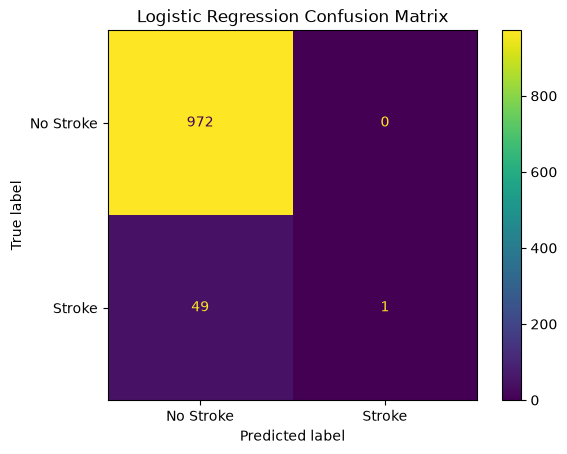

In [11]:
lr = LogisticRegression(max_iter=2000, random_state=SEED)

lr_results = evaluate_model(
    lr,
    X_train_scaled, y_train,
    X_test_scaled, y_test
)

print(pd.Series(lr_results).round(4))

lr_pred = lr.predict(X_test_scaled)

print("\nConfusion matrix:")
print(confusion_matrix(y_test, lr_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test, lr_pred,
    display_labels=["No Stroke", "Stroke"]
)
plt.title("Logistic Regression Confusion Matrix")
plt.show()

### 3.

In [10]:
def evaluate_model(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, y_prob),
        "PR AUC": average_precision_score(y_test, y_prob)
    }

### Questions: (A):
The majority-class baseline may achieve high accuracy because most patients did not have a stroke. However, it fails to identify stroke patients. Logistic Regression should be judged using recall, precision, F1, ROC AUC and PR AUC as well as accuracy.

### (B):
A false negative means the model predicts that a patient did not have a stroke when the actual label is stroke. In a hospital screening system, this could mean missing a patient who needs further medical assessment. Recall is particularly important because it measures how many actual stroke cases are detected.

## Part-2:
### 2.1 Validation curve
#### 1,2.


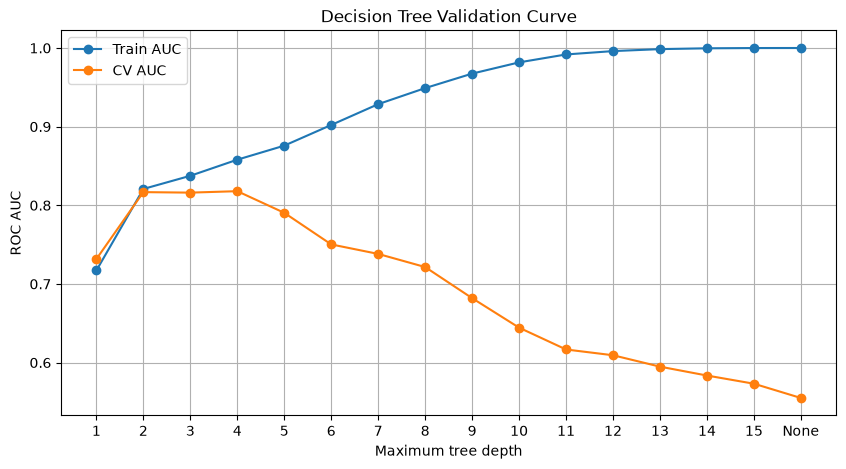

Best depth: 4
Best CV AUC: 0.818
Depth  Train AUC  CV AUC
    1     0.7171  0.7317
    2     0.8208  0.8168
    3     0.8375  0.8161
    4     0.8580  0.8180
    5     0.8758  0.7904
    6     0.9021  0.7503
    7     0.9286  0.7382
    8     0.9490  0.7215
    9     0.9674  0.6819
   10     0.9817  0.6444
   11     0.9918  0.6167
   12     0.9961  0.6093
   13     0.9986  0.5948
   14     0.9996  0.5835
   15     0.9999  0.5731
 None     1.0000  0.5550


In [12]:
depths = list(range(1, 16)) + [None]

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=SEED
)

train_auc = []
cv_auc = []

for depth in depths:
    tree = DecisionTreeClassifier(
        max_depth=depth, random_state=SEED
    )

    tree.fit(X_train, y_train)

    train_prob = tree.predict_proba(X_train)[:, 1]
    train_auc.append(roc_auc_score(y_train, train_prob))

    scores = cross_val_score(
        tree, X_train, y_train,
        cv=cv, scoring="roc_auc", n_jobs=-1
    )
    cv_auc.append(scores.mean())

plt.figure(figsize=(10, 5))
plt.plot(range(len(depths)), train_auc, marker="o", label="Train AUC")
plt.plot(range(len(depths)), cv_auc, marker="o", label="CV AUC")
plt.xticks(range(len(depths)), [str(d) for d in depths])
plt.xlabel("Maximum tree depth")
plt.ylabel("ROC AUC")
plt.title("Decision Tree Validation Curve")
plt.legend()
plt.grid(True)
plt.show()

best_idx = int(np.argmax(cv_auc))
print("Best depth:", depths[best_idx])
print("Best CV AUC:", round(cv_auc[best_idx], 4))

validation_results = pd.DataFrame({
    "Depth": [str(d) for d in depths],
    "Train AUC": train_auc,
    "CV AUC": cv_auc
})

print(validation_results.round(4).to_string(index=False))

### Task 2.2:

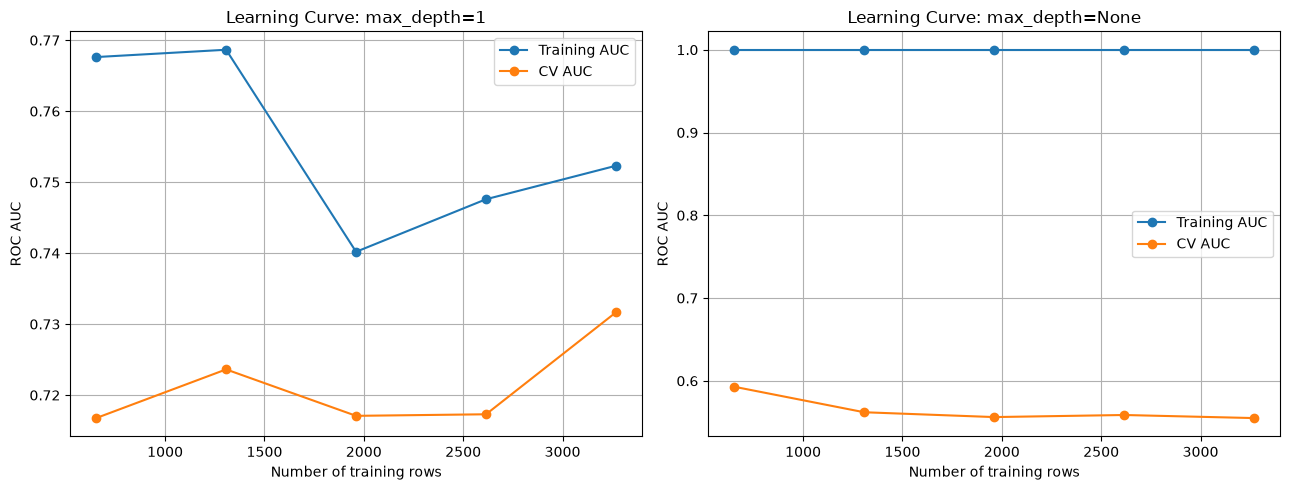

In [13]:
def plot_learning_curve(depth, ax):
    tree = DecisionTreeClassifier(
        max_depth=depth, random_state=SEED
    )

    sizes, train_scores, valid_scores = learning_curve(
        tree,
        X_train, y_train,
        train_sizes=np.linspace(0.2, 1.0, 5),
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    ax.plot(sizes, train_scores.mean(axis=1),
            marker="o", label="Training AUC")
    ax.plot(sizes, valid_scores.mean(axis=1),
            marker="o", label="CV AUC")
    ax.set_title(f"Learning Curve: max_depth={depth}")
    ax.set_xlabel("Number of training rows")
    ax.set_ylabel("ROC AUC")
    ax.legend()
    ax.grid(True)


fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plot_learning_curve(1, axes[0])
plot_learning_curve(None, axes[1])

plt.tight_layout()
plt.show()

### Task 2.3:

In [14]:
rng = np.random.default_rng(SEED)
depths_to_test = [1, 3, None]
variance_results = []

for depth in depths_to_test:
    predictions = []

    for _ in range(40):
        idx = rng.choice(
            len(X_train), size=len(X_train), replace=True
        )

        X_boot = X_train.iloc[idx]
        y_boot = y_train.iloc[idx]

        tree = DecisionTreeClassifier(
            max_depth=depth, random_state=SEED
        )
        tree.fit(X_boot, y_boot)

        predictions.append(
            tree.predict_proba(X_test)[:, 1]
        )

    probs = np.array(predictions)

    individual_auc = [
        roc_auc_score(y_test, p) for p in probs
    ]

    average_prob = probs.mean(axis=0)

    variance_results.append({
        "Depth": str(depth),
        "Mean Prediction Variance": probs.var(axis=0).mean(),
        "Mean Individual AUC": np.mean(individual_auc),
        "AUC of Averaged Predictions": roc_auc_score(
            y_test, average_prob
        )
    })

variance_df = pd.DataFrame(variance_results)
print(variance_df.round(4).to_string(index=False))

Depth  Mean Prediction Variance  Mean Individual AUC  AUC of Averaged Predictions
    1                    0.0007               0.7623                       0.8132
    3                    0.0017               0.7963                       0.8336
 None                    0.0420               0.5542                       0.7701


### Questions: (A):
Use your validation table to identify the depths. Low depths with poor training and CV AUC indicate underfitting. Depths with high training AUC but a much lower CV AUC indicate overfitting. Choose the depth with the highest CV AUC, considering the size of the train–CV gap.

### (B):
High bias is indicated by poor training and validation scores that remain close together. High variance is indicated by a large gap between training and validation scores. More data may reduce variance, but it will not necessarily fix a model that is too simple.

### (C):
Deeper trees can fit more complex patterns but may become more sensitive to the training sample. Averaging predictions can reduce variance, which is one of the main ideas behind Random Forest.

### (D):
Bias is error caused by a model being too simple. Variance is sensitivity to changes in the training data. A depth-1 tree is likely to have high bias; a depth-3 tree provides a compromise; an unlimited-depth tree can have high variance.


## Part-3: 
### Task 3.1

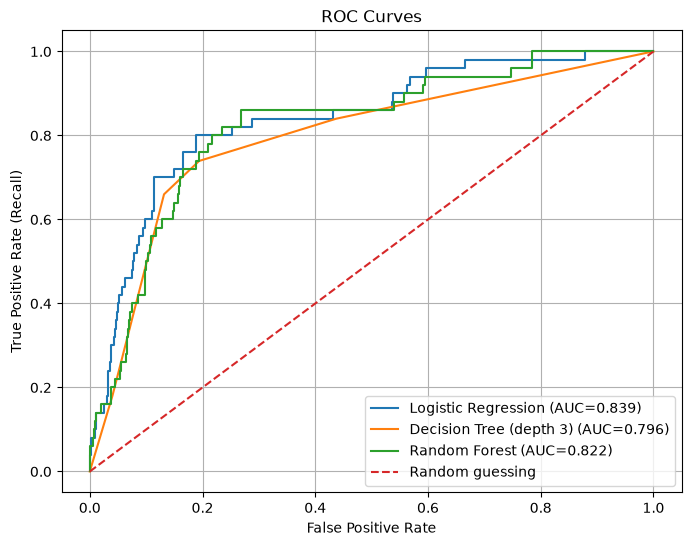

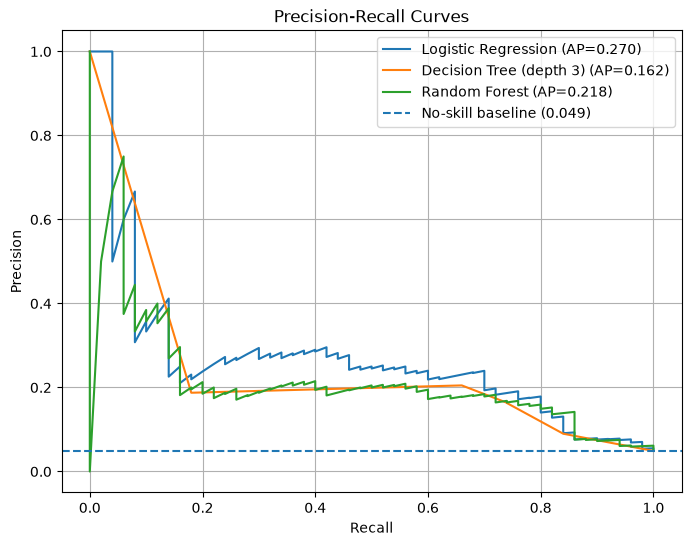

                         ROC AUC  PR AUC
Logistic Regression       0.8393  0.2696
Decision Tree (depth 3)   0.7956  0.1621
Random Forest             0.8215  0.2183


In [15]:
models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, random_state=SEED),
        X_train_scaled, X_test_scaled
    ),
    "Decision Tree (depth 3)": (
        DecisionTreeClassifier(max_depth=3, random_state=SEED),
        X_train, X_test
    ),
    "Random Forest": (
        RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=5,
            random_state=SEED,
            n_jobs=-1
        ),
        X_train, X_test
    )
}

model_probs = {}
model_curves_results = {}

for name, (model, xtr, xte) in models.items():
    model.fit(xtr, y_train)
    prob = model.predict_proba(xte)[:, 1]
    model_probs[name] = prob

    model_curves_results[name] = {
        "ROC AUC": roc_auc_score(y_test, prob),
        "PR AUC": average_precision_score(y_test, prob)
    }

# ROC curves
plt.figure(figsize=(8, 6))

for name, prob in model_probs.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], "--", label="Random guessing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves")
plt.legend()
plt.grid(True)
plt.show()

# Precision-Recall curves
plt.figure(figsize=(8, 6))
stroke_rate = y_test.mean()

for name, prob in model_probs.items():
    precision, recall, _ = precision_recall_curve(y_test, prob)
    ap = average_precision_score(y_test, prob)
    plt.plot(recall, precision, label=f"{name} (AP={ap:.3f})")

plt.axhline(
    stroke_rate, linestyle="--",
    label=f"No-skill baseline ({stroke_rate:.3f})"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend()
plt.grid(True)
plt.show()

print(pd.DataFrame(model_curves_results).T.round(4))

### Task 3.2
#### 1.

In [16]:
lr_cv = LogisticRegression(max_iter=2000, random_state=SEED)

oof_prob = cross_val_predict(
    lr_cv,
    X_train_scaled, y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

thresholds = np.sort(np.unique(oof_prob))

valid_thresholds = []

for threshold in thresholds:
    pred = (oof_prob >= threshold).astype(int)
    r = recall_score(y_train, pred, zero_division=0)

    if r >= 0.80:
        valid_thresholds.append(threshold)

if not valid_thresholds:
    raise ValueError("No threshold achieved recall >= 0.80")

best_threshold = max(valid_thresholds)

print("Chosen threshold:", round(best_threshold, 4))
print("Training OOF recall:",
      round(recall_score(
          y_train, (oof_prob >= best_threshold).astype(int)
      ), 4))

Chosen threshold: 0.0507
Training OOF recall: 0.804


#### 2.

In [17]:
lr_cv.fit(X_train_scaled, y_train)

test_prob = lr_cv.predict_proba(X_test_scaled)[:, 1]
threshold_pred = (test_prob >= best_threshold).astype(int)

cm = confusion_matrix(y_test, threshold_pred)
tn, fp, fn, tp = cm.ravel()

print("Test recall:", round(recall_score(
    y_test, threshold_pred, zero_division=0
), 4))

print("Test precision:", round(precision_score(
    y_test, threshold_pred, zero_division=0
), 4))

print("Confusion matrix:\n", cm)
print("Patients flagged:", int(threshold_pred.sum()))
print("False alarms:", int(fp))
print("Missed strokes:", int(fn))

Test recall: 0.82
Test precision: 0.1344
Confusion matrix:
 [[708 264]
 [  9  41]]
Patients flagged: 305
False alarms: 264
Missed strokes: 9


### Question: (A):
ROC AUC measures how well a model ranks stroke patients above non-stroke patients across different thresholds. Recall at the default threshold of 0.5 measures performance at just one operating point. A model can rank patients reasonably well but still miss many stroke cases at that threshold.

### (B)
The Precision-Recall curve is often more informative for this highly imbalanced dataset because it focuses on the positive class. Its no-skill baseline is the stroke rate, so precision substantially above that line indicates useful positive-class predictions.

### (C):
Use your measured precision, recall, and false-alarm count. Higher recall can help identify more patients who need further assessment, but it may also flag many patients who did not have a stroke. The hospital must balance the cost of additional assessments against the danger of missed cases.


## Part-4:
### Task 4.1:

In [18]:
def rebalance_data(Xtr, ytr, method):
    if method == "None":
        return Xtr, ytr

    if method == "Undersampling":
        sampler = RandomUnderSampler(random_state=SEED)

    elif method == "Oversampling":
        sampler = RandomOverSampler(random_state=SEED)

    elif method == "SMOTE":
        sampler = SMOTE(random_state=SEED)

    else:
        raise ValueError("Unknown resampling method")

    return sampler.fit_resample(Xtr, ytr)


methods = [
    "None", "Balanced weights",
    "Undersampling", "Oversampling", "SMOTE"
]

resampling_results = []

for model_name in ["Logistic Regression", "Random Forest"]:
    for method in methods:

        if model_name == "Logistic Regression":
            Xtr, Xte = X_train_scaled, X_test_scaled
            class_weight = (
                "balanced" if method == "Balanced weights" else None
            )
            model = LogisticRegression(
                max_iter=2000,
                random_state=SEED,
                class_weight=class_weight
            )

        else:
            Xtr, Xte = X_train, X_test
            class_weight = (
                "balanced" if method == "Balanced weights" else None
            )
            model = RandomForestClassifier(
                n_estimators=200,
                min_samples_leaf=5,
                random_state=SEED,
                n_jobs=-1,
                class_weight=class_weight
            )

        if method in ["Undersampling", "Oversampling", "SMOTE"]:
            Xres, yres = rebalance_data(Xtr, y_train, method)
        else:
            Xres, yres = Xtr, y_train

        model.fit(Xres, yres)

        prob = model.predict_proba(Xte)[:, 1]
        pred = model.predict(Xte)

        resampling_results.append({
            "Model": model_name,
            "Method": method,
            "Training rows": len(yres),
            "Training strokes": int(np.sum(yres)),
            "Precision": precision_score(
                y_test, pred, zero_division=0
            ),
            "Recall": recall_score(
                y_test, pred, zero_division=0
            ),
            "F1": f1_score(
                y_test, pred, zero_division=0
            ),
            "ROC AUC": roc_auc_score(y_test, prob),
            "PR AUC": average_precision_score(y_test, prob)
        })

resampling_df = pd.DataFrame(resampling_results)

print(resampling_df.round(4).to_string(index=False))

              Model           Method  Training rows  Training strokes  Precision  Recall     F1  ROC AUC  PR AUC
Logistic Regression             None           4087               199     1.0000    0.02 0.0392   0.8393  0.2696
Logistic Regression Balanced weights           4087               199     0.1347    0.80 0.2305   0.8396  0.2596
Logistic Regression    Undersampling            398               199     0.1246    0.82 0.2164   0.8350  0.2333
Logistic Regression     Oversampling           7776              3888     0.1333    0.80 0.2286   0.8385  0.2591
Logistic Regression            SMOTE           7776              3888     0.1347    0.80 0.2305   0.8407  0.2957
      Random Forest             None           4087               199     0.0000    0.00 0.0000   0.8215  0.2183
      Random Forest Balanced weights           4087               199     0.1771    0.68 0.2810   0.8144  0.2050
      Random Forest    Undersampling            398               199     0.1032    0.84 0.1838 

### Task 4.2:

In [20]:
# Fill missing values before scaling
imputer_all = SimpleImputer(strategy="median")

X_all_clean = pd.DataFrame(
    imputer_all.fit_transform(X),
    columns=X.columns,
    index=X.index
)

# Scale the cleaned data
scaler_all = StandardScaler()

X_all_scaled = pd.DataFrame(
    scaler_all.fit_transform(X_all_clean),
    columns=X.columns,
    index=X.index
)

# WRONG ORDER: SMOTE before splitting (for demonstration only)
X_smote_all, y_smote_all = SMOTE(
    random_state=SEED
).fit_resample(X_all_scaled, y)

# Now split the resampled data
X_bad_train, X_bad_test, y_bad_train, y_bad_test = train_test_split(
    X_smote_all,
    y_smote_all,
    test_size=0.20,
    stratify=y_smote_all,
    random_state=SEED
)

bad_rf = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED,
    n_jobs=-1
)

bad_rf.fit(X_bad_train, y_bad_train)
bad_prob = bad_rf.predict_proba(X_bad_test)[:, 1]
bad_pred = bad_rf.predict(X_bad_test)

# Correct SMOTE-after-split comparison
X_correct_smote, y_correct_smote = SMOTE(
    random_state=SEED
).fit_resample(X_train, y_train)

correct_rf = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED,
    n_jobs=-1
)

correct_rf.fit(X_correct_smote, y_correct_smote)
correct_prob = correct_rf.predict_proba(X_test)[:, 1]
correct_pred = correct_rf.predict(X_test)

def metrics_from_predictions(y_true, pred, prob):
    return {
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_true, prob),
        "PR AUC": average_precision_score(y_true, prob)
    }

leakage_comparison = pd.DataFrame([
    {
        "Method": "WRONG: SMOTE before split",
        **metrics_from_predictions(y_bad_test, bad_pred, bad_prob)
    },
    {
        "Method": "Correct: SMOTE after split",
        **metrics_from_predictions(y_test, correct_pred, correct_prob)
    }
])

print(leakage_comparison.round(4).to_string(index=False))

                    Method  Precision  Recall     F1  ROC AUC  PR AUC
 WRONG: SMOTE before split     0.8909  0.9496 0.9193   0.9790  0.9794
Correct: SMOTE after split     0.6667  0.0400 0.0755   0.8046  0.2424


### Questions: (A):
Compare precision, recall and ROC AUC in your table. Resampling often changes the decision boundary and the number of positive predictions, affecting precision and recall. ROC AUC may change less because it evaluates ranking across thresholds, but its direction and magnitude depend on the data and model.

### (B):
Use the table to identify one difference. Logistic Regression learns a linear decision boundary, whereas Random Forest learns nonlinear splits. Resampling may therefore affect their decision boundaries differently.

### (C):
SMOTE uses relationships between neighboring minority-class observations to create synthetic examples. When it runs before splitting, test information can influence the synthetic training data. The resulting evaluation does not represent a clean test on independent, untouched patients.

### (D):
Choose the method with an acceptable balance of recall, precision, PR AUC and operational cost. Class weighting is a simple option because it does not discard or synthesize patient records. A resampling method may be preferable if your results show a meaningful improvement in stroke detection without an unacceptable increase in false alarms.


## Part-5:

### task 5.1:

Model  Decision Tree (depth 3)  Decision Tree (unlimited)  \
Noise                                                       
0.00                    0.7956                     0.5722   
0.05                    0.8014                     0.5550   
0.10                    0.8029                     0.5310   
0.20                    0.7263                     0.5060   

Model  Logistic Regression  Random Forest  
Noise                                      
0.00                0.8393         0.8215  
0.05                0.8239         0.7896  
0.10                0.8132         0.7459  
0.20                0.7745         0.6699  


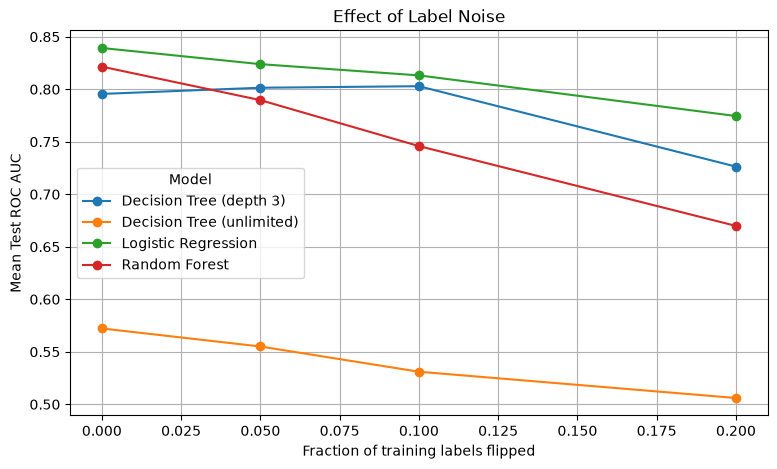

In [21]:
def add_label_noise(y, fraction, seed):
    rng = np.random.default_rng(seed)
    noisy_y = np.asarray(y).copy()

    n_flip = int(round(fraction * len(noisy_y)))
    indices = rng.choice(
        len(noisy_y), size=n_flip, replace=False
    )

    noisy_y[indices] = 1 - noisy_y[indices]
    return noisy_y


def get_models():
    return {
        "Logistic Regression": LogisticRegression(
            max_iter=2000, random_state=SEED
        ),
        "Decision Tree (depth 3)": DecisionTreeClassifier(
            max_depth=3, random_state=SEED
        ),
        "Decision Tree (unlimited)": DecisionTreeClassifier(
            max_depth=None, random_state=SEED
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=5,
            random_state=SEED,
            n_jobs=-1
        )
    }


label_noise_results = []

for fraction in [0, 0.05, 0.10, 0.20]:
    repeats = 1 if fraction == 0 else 5

    for repeat in range(repeats):
        noisy_y = add_label_noise(
            y_train, fraction, SEED + repeat
        )

        for name, model in get_models().items():

            if name == "Logistic Regression":
                Xtr, Xte = X_train_scaled, X_test_scaled
            else:
                Xtr, Xte = X_train, X_test

            model.fit(Xtr, noisy_y)
            prob = model.predict_proba(Xte)[:, 1]

            label_noise_results.append({
                "Noise": fraction,
                "Repeat": repeat,
                "Model": name,
                "ROC AUC": roc_auc_score(y_test, prob)
            })

label_noise_df = pd.DataFrame(label_noise_results)

label_noise_summary = (
    label_noise_df.groupby(["Noise", "Model"])["ROC AUC"]
    .mean().unstack()
)

print(label_noise_summary.round(4))

label_noise_summary.plot(
    marker="o", figsize=(9, 5)
)
plt.xlabel("Fraction of training labels flipped")
plt.ylabel("Mean Test ROC AUC")
plt.title("Effect of Label Noise")
plt.grid(True)
plt.show()

### Task 5.2:

Model        Decision Tree (depth 3)  Decision Tree (unlimited)  \
Noise level                                                       
0.0                           0.7956                     0.5722   
0.5                           0.7995                     0.5751   
1.0                           0.7610                     0.5271   
2.0                           0.6942                     0.5283   

Model        Logistic Regression  Random Forest  
Noise level                                      
0.0                       0.8393         0.8215  
0.5                       0.8337         0.8082  
1.0                       0.8098         0.7782  
2.0                       0.7690         0.7352  


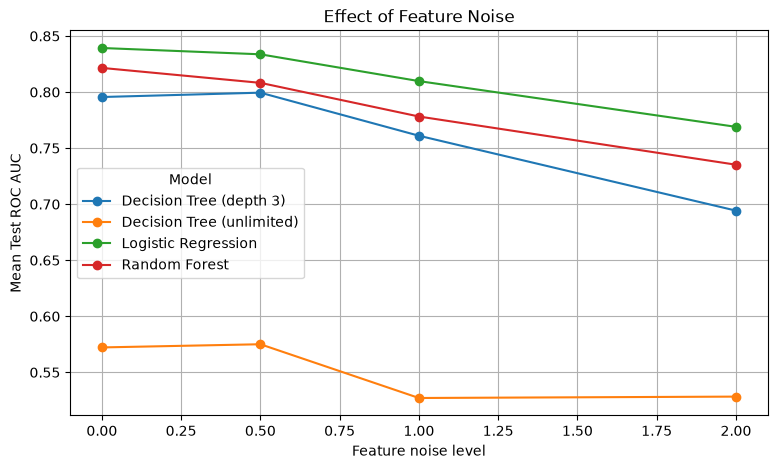

In [22]:
def add_feature_noise(X_original, level, seed):
    rng = np.random.default_rng(seed)
    X_noisy = X_original.copy()

    for col in ["age", "avg_glucose_level", "bmi"]:
        std = X_original[col].std()

        X_noisy[col] = (
            X_original[col].to_numpy()
            + rng.normal(0, 1, len(X_original)) * std * level
        )

    return X_noisy


feature_noise_results = []

for level in [0, 0.5, 1, 2]:
    repeats = 1 if level == 0 else 5

    for repeat in range(repeats):
        X_noisy = add_feature_noise(
            X_train, level, SEED + repeat
        )

        # Fit scaling on the noisy training data only
        noisy_scaler = StandardScaler()

        X_noisy_scaled = pd.DataFrame(
            noisy_scaler.fit_transform(X_noisy),
            columns=X_noisy.columns,
            index=X_noisy.index
        )

        X_test_scaled_for_noise = pd.DataFrame(
            noisy_scaler.transform(X_test),
            columns=X_test.columns,
            index=X_test.index
        )

        for name, model in get_models().items():

            if name == "Logistic Regression":
                Xtr = X_noisy_scaled
                Xte = X_test_scaled_for_noise
            else:
                Xtr = X_noisy
                Xte = X_test

            model.fit(Xtr, y_train)
            prob = model.predict_proba(Xte)[:, 1]

            feature_noise_results.append({
                "Noise level": level,
                "Repeat": repeat,
                "Model": name,
                "ROC AUC": roc_auc_score(y_test, prob)
            })

feature_noise_df = pd.DataFrame(feature_noise_results)

feature_noise_summary = (
    feature_noise_df.groupby(["Noise level", "Model"])["ROC AUC"]
    .mean().unstack()
)

print(feature_noise_summary.round(4))

feature_noise_summary.plot(
    marker="o", figsize=(9, 5)
)
plt.xlabel("Feature noise level")
plt.ylabel("Mean Test ROC AUC")
plt.title("Effect of Feature Noise")
plt.grid(True)
plt.show()

### Task 5.3:

In [23]:
smote_noise_results = []

for repeat in range(3):
    noisy_y = add_label_noise(
        y_train, 0.10, SEED + 100 + repeat
    )

    for model_name in ["Logistic Regression", "Random Forest"]:
        for use_smote in [False, True]:

            if model_name == "Logistic Regression":
                Xtr, Xte = X_train_scaled, X_test_scaled
                model = LogisticRegression(
                    max_iter=2000, random_state=SEED
                )
            else:
                Xtr, Xte = X_train, X_test
                model = RandomForestClassifier(
                    n_estimators=200,
                    min_samples_leaf=5,
                    random_state=SEED,
                    n_jobs=-1
                )

            if use_smote:
                Xfit, yfit = SMOTE(
                    random_state=SEED + repeat
                ).fit_resample(Xtr, noisy_y)
            else:
                Xfit, yfit = Xtr, noisy_y

            model.fit(Xfit, yfit)
            prob = model.predict_proba(Xte)[:, 1]

            smote_noise_results.append({
                "Repeat": repeat,
                "Model": model_name,
                "SMOTE": use_smote,
                "ROC AUC": roc_auc_score(y_test, prob),
                "PR AUC": average_precision_score(y_test, prob)
            })

smote_noise_df = pd.DataFrame(smote_noise_results)

print(
    smote_noise_df.groupby(["Model", "SMOTE"])[
        ["ROC AUC", "PR AUC"]
    ].mean().round(4)
)

                           ROC AUC  PR AUC
Model               SMOTE                 
Logistic Regression False   0.8063  0.2339
                    True    0.7918  0.2223
Random Forest       False   0.7859  0.1942
                    True    0.7025  0.1432


### Questions: (A):
Compare your tables at the highest noise level. A deep decision tree may be especially sensitive to noise because it can learn individual misleading observations. However, the model that performs worst in your experiment must be identified from your actual AUC values.

### (B):
Compare the results at comparable noise levels. Label noise directly teaches the model incorrect outcomes, whereas feature noise corrupts input measurements. State which caused the greater AUC reduction in your experiment.

### (C):
Compare the mean ROC AUC and PR AUC with and without SMOTE. SMOTE may help or hurt, depending on the data. With noisy labels, it can amplify errors by creating synthetic minority samples around incorrectly labelled observations.



## Part-6:
### 1.

In [24]:
final_model = LogisticRegression(
    max_iter=2000, random_state=SEED
)

final_model.fit(X_train_scaled, y_train)

final_prob = final_model.predict_proba(X_test_scaled)[:, 1]

# Default threshold
pred_default = (final_prob >= 0.5).astype(int)

# Threshold chosen using training OOF probabilities in Part 3
pred_chosen = (final_prob >= best_threshold).astype(int)


def final_metrics(y_true, pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, pred, labels=[0, 1]
    ).ravel()

    return {
        "Precision": precision_score(
            y_true, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, pred, zero_division=0
        ),
        "False alarms": int(fp),
        "Missed strokes": int(fn)
    }


final_comparison = pd.DataFrame([
    {
        "Approach": "Default threshold (0.5)",
        **final_metrics(y_test, pred_default)
    },
    {
        "Approach": f"Chosen threshold ({best_threshold:.4f})",
        **final_metrics(y_test, pred_chosen)
    }
])

print(final_comparison.round(4).to_string(index=False))

                 Approach  Precision  Recall     F1  False alarms  Missed strokes
  Default threshold (0.5)     1.0000    0.02 0.0392             0              49
Chosen threshold (0.0507)     0.1344    0.82 0.2310           264               9


### 2.
## Executive Summary — Lab 09

This lab investigated bias, variance and class imbalance using the Stroke Prediction Dataset.

The selected model was **[Logistic Regresion]**, using **[SMOTE]**.

On the test set, the model achieved a recall of **[0.82]** and a precision of **[0.134]**.

It produced **[264]** false alarms and missed **[9]** actual stroke cases.

The selected approach was chosen because **[due to the nature of criticallity the prefered false alarms were safer than that of the missed acctual cases]**.

Data leakage was avoided by fitting preprocessing steps on training data and applying resampling only after splitting.

The decision threshold was selected using training out-of-fold predictions, and the final results were evaluated on the untouched test set.

One limitation is that the test set contains relatively few stroke cases, so the measured performance may vary on new patients.


## (A):
The most surprising result was that a model could achieve high accuracy while missing many stroke cases. This demonstrated that accuracy alone is insufficient for an imbalanced medical dataset.

## (B):
I would tune the model's hyperparameters, compare more thresholds using training-only validation, and test the selected approach using repeated stratified cross-validation. I would also investigate methods that handle categorical features appropriately and assess the uncertainty of the recall estimate.